# 10 Plot extreme changes conditioned on AMOC evolution for end of simulation #

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import xarray as xr
import pandas as pd
import netCDF4 as nc
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting
from cdrmip_extremes.load_processed import load_extremes
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

## Load Data ##

In [3]:
expt = '1pctCO2-cdr'

#### From previous notebook we have ####

In [4]:
amoc_changes = {
    'CNRM-ESM2-1': -6.69,
    'MIROC-ES2L': -1.17,
    'UKESM1-0-LL': 1.1,
    'CanESM5': 3.01,
    'CESM2': 3.13,
    'GFDL-ESM4': 3.23,
    'ACCESS-ESM1-5': 4.04,
    'NorESM2-LM': 5.3
}
models_amoc_ordered = list(amoc_changes.keys())
models_amoc_ordered

['CNRM-ESM2-1',
 'MIROC-ES2L',
 'UKESM1-0-LL',
 'CanESM5',
 'CESM2',
 'GFDL-ESM4',
 'ACCESS-ESM1-5',
 'NorESM2-LM']

In [5]:
ext_data = load_extremes(
    PROC_DIR, 'CDRMIP',
    outputs=['exceedances_matching_median_multimodel', 'branch_differences_matching_median_multimodel',
             'agreement_matching',
             'gwl_period_extremes_matching',
            ],
    model_order=CDR_MODELS,
)
exceedances = ext_data['exceedances_matching_median_multimodel']
differences = ext_data['branch_differences_matching_median_multimodel']
agreement = ext_data['agreement_matching']
ext_month_tas = ext_data['gwl_period_extremes_matching']

  sort_models: no order defined for ['multi_model_median'], appending at end
  sort_models: no order defined for ['multi_model_median'], appending at end


In [6]:
heat_freq_differences = {
    model: differences[model][expt]['heat'] for model in models_amoc_ordered
}
cold_freq_differences = {
    model: differences[model][expt]['cold'] for model in models_amoc_ordered
}

#### Load extreme month temperature data ####

In [7]:
ext_month_tas = {
    model: ext_month_tas[model][expt][None] for model in models_amoc_ordered
}

### Determine differences ###

In [9]:
ext_month_tas_differences = {
    model: stats.gwl_branch_difference(ds)
    for model, ds in ext_month_tas.items()
}

## Plot ##

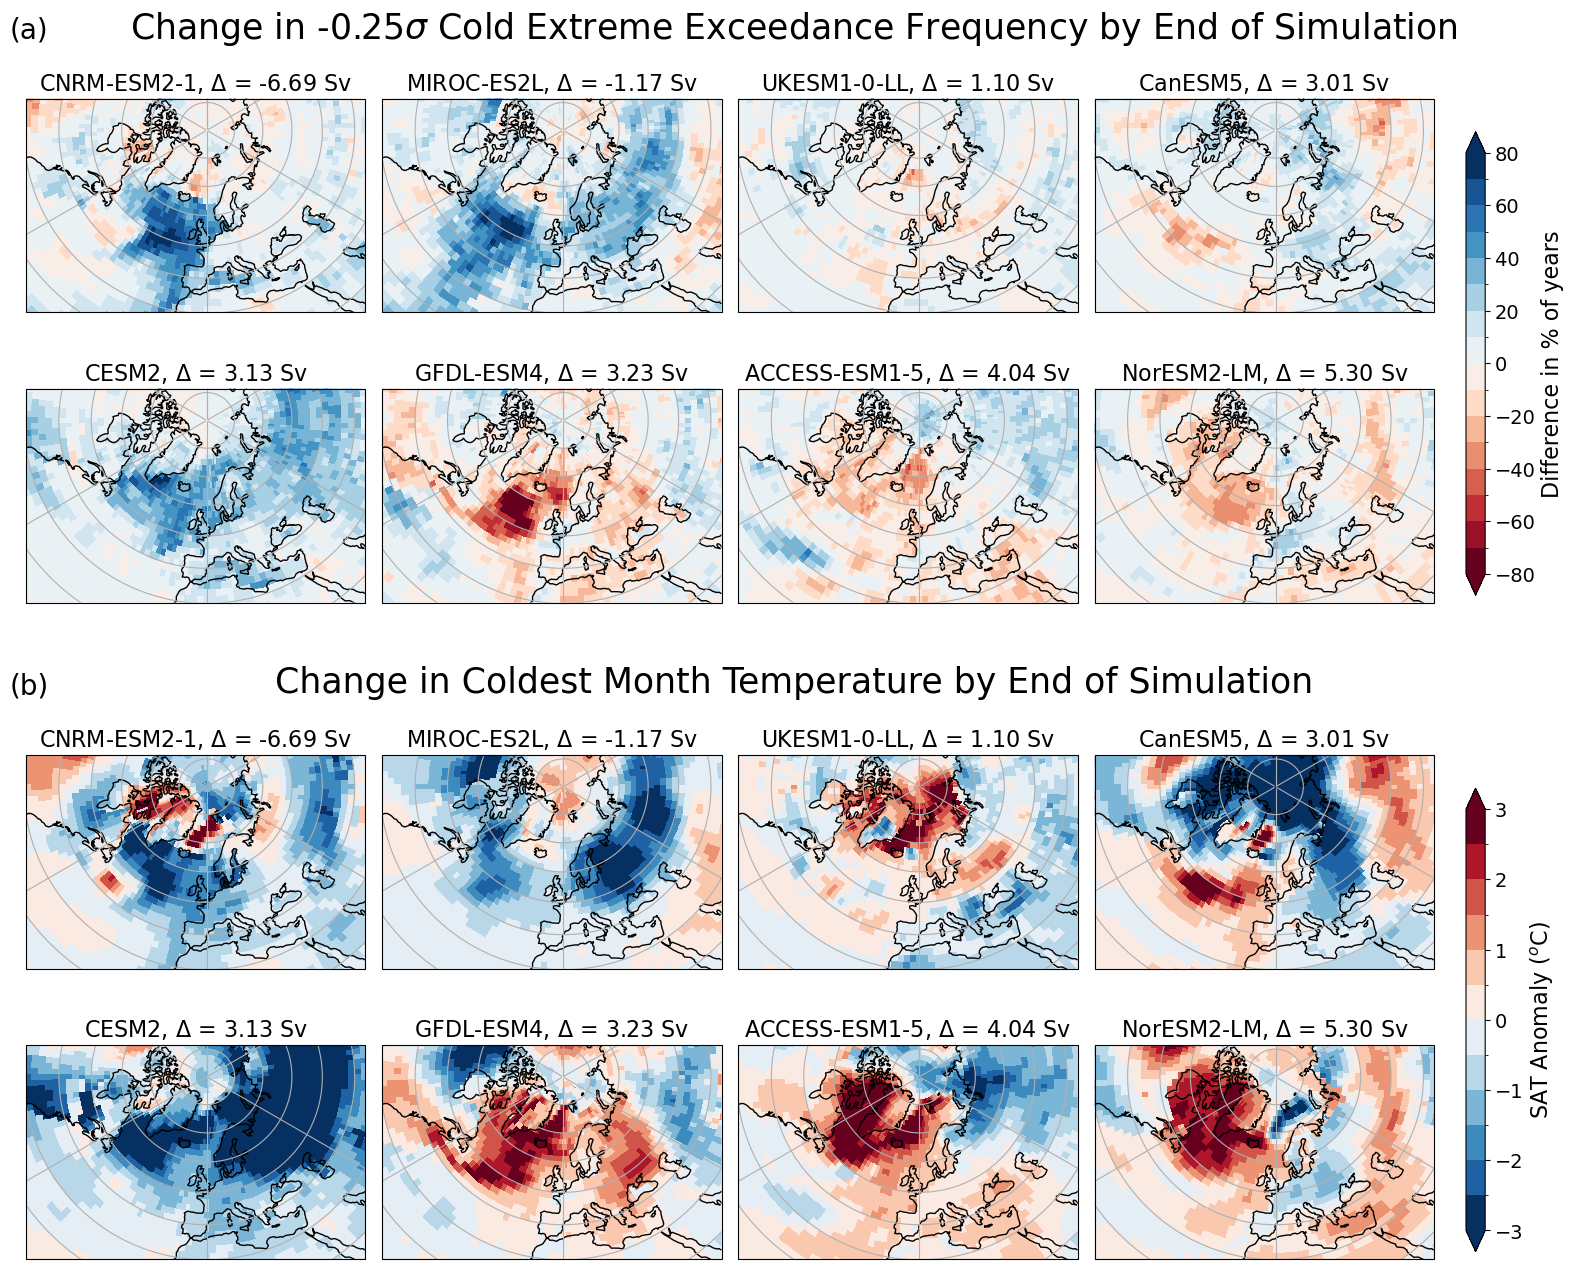

In [11]:
fig = plotting.plot_freq_and_intens_amoc_stereo(
    'Cold',
    cold_freq_differences,
    ext_month_tas_differences,
    1.5,
    'sigma1',
    freq_levels=np.linspace(-80, 80, 17),
    intens_levels=np.linspace(-3, 3, 13),
    amoc_changes=amoc_changes,
    period='final'
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S26.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Plot mean changes grouped by AMOC sensitivity ##

In [24]:
AMOC_models = ["CESM2","MIROC-ES2L","NorESM2-LM",'CNRM-ESM2-1',]
non_AMOC_models = ['ACCESS-ESM1-5','CanESM5','GFDL-ESM4',"UKESM1-0-LL"]

In [25]:
AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_heat_freq_mean = xr.concat([heat_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')

In [29]:
AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_cold_freq_mean = xr.concat([cold_freq_differences[model] for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')

In [30]:
cbar_kwargs = {
        "fraction": 0.02, "aspect": 20,
        "label": "% Years", 'orientation': 'vertical',
        'location': 'right', 'pad': 0.01,
        'anchor': (0.5, -4), 'extend': 'both'
    }

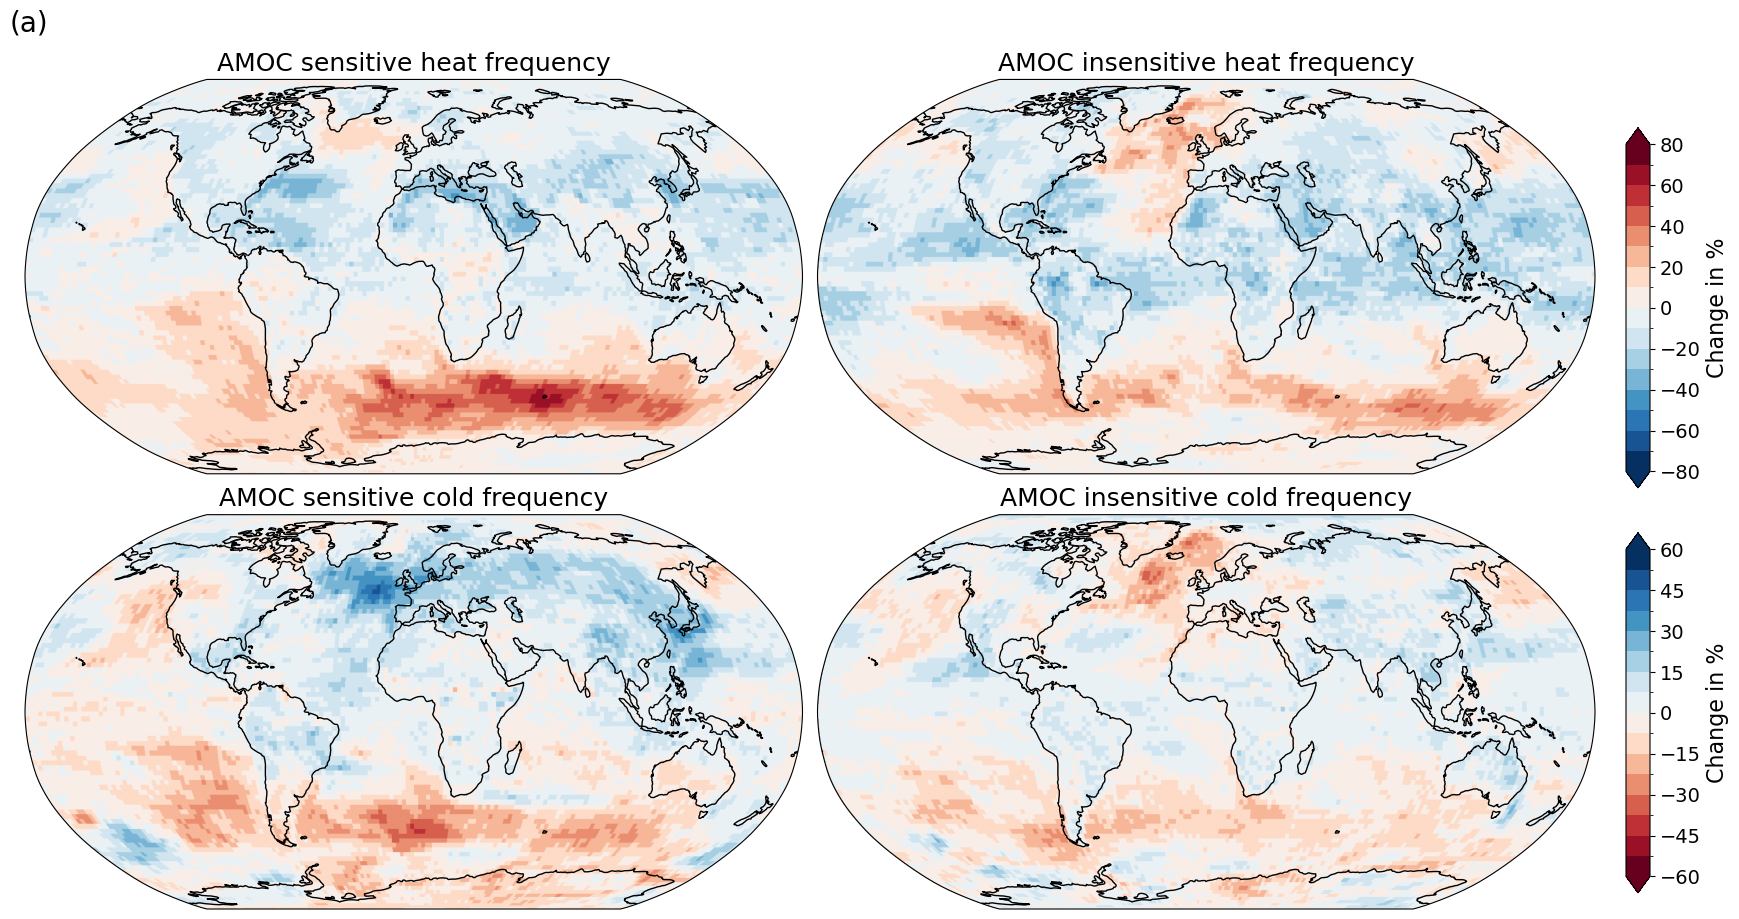

In [38]:
to_plot_heat = {
    'AMOC sensitive heat frequency':AMOC_heat_freq_mean.sigma2.isel(gwl=0),
    'AMOC insensitive heat frequency':non_AMOC_heat_freq_mean.sigma2.isel(gwl=0),
}
to_plot_cold = {
    'AMOC sensitive cold frequency':AMOC_cold_freq_mean.sigma1.isel(gwl=0),
    'AMOC insensitive cold frequency':non_AMOC_cold_freq_mean.sigma1.isel(gwl=0),
}

levels_heat = np.linspace(-80,80,17)
norm_heat = BoundaryNorm(levels_heat, ncolors=plt.cm.RdBu_r.N, clip=True)

levels_cold = np.linspace(-60,60,17)
norm_cold = BoundaryNorm(levels_cold, ncolors=plt.cm.RdBu.N, clip=True)

fig, axes = plt.subplots(2,2,subplot_kw={'projection': ccrs.Robinson()}, figsize=(16, 9))


for (model,da), ax in zip(to_plot_heat.items(),axes.flat[:2]):

    im = ax.imshow(
        da,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        norm=norm_heat,
        origin='lower',
        extent = (0,360,-90,90)
    )        
    ax.coastlines()
    # ax.gridlines(draw_labels=False)
    ax.set_title(model,fontsize=18)

cbar_ax1 = fig.add_axes([1.01,0.5,0.015,0.4])
cbar1 = fig.colorbar(im,
                    cax=cbar_ax1,
                    **cbar_kwargs
                   )
cbar1.ax.tick_params(labelsize=14) 
cbar1.set_label("Change in %", fontsize=16)

for (model,da), ax in zip(to_plot_cold.items(),axes.flat[2:]):

    im = ax.imshow(
        da,
        transform=ccrs.PlateCarree(),
        cmap='RdBu',
        norm=norm_cold,
        origin='lower',
        extent = (0,360,-90,90)
    )        
    # Add coastlines and grid
    ax.coastlines()
    # ax.gridlines(draw_labels=False)
    ax.set_title(model,fontsize=18)

cbar_ax2 = fig.add_axes([1.01,0.05,0.015,0.4])
cbar2 = fig.colorbar(im,
                    cax=cbar_ax2,
                    **cbar_kwargs
                   )
cbar2.ax.tick_params(labelsize=14)  # Adjust tick label size
cbar2.set_label("Change in %", fontsize=16)

fig.text(0,1.0,
         '(a)',
         fontsize=20,
         va='bottom',
         ha='left'
        )

fig.tight_layout()

In [40]:
AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in AMOC_models],
                                  dim='model',
                                 compat='override',
                                 coords='minimal').mean(dim='model')
non_AMOC_ext_month_tas_mean = xr.concat([ext_month_tas_differences[model].tas for model in non_AMOC_models],
                                      dim='model',
                                      compat='override',
                                      coords='minimal').mean(dim='model')

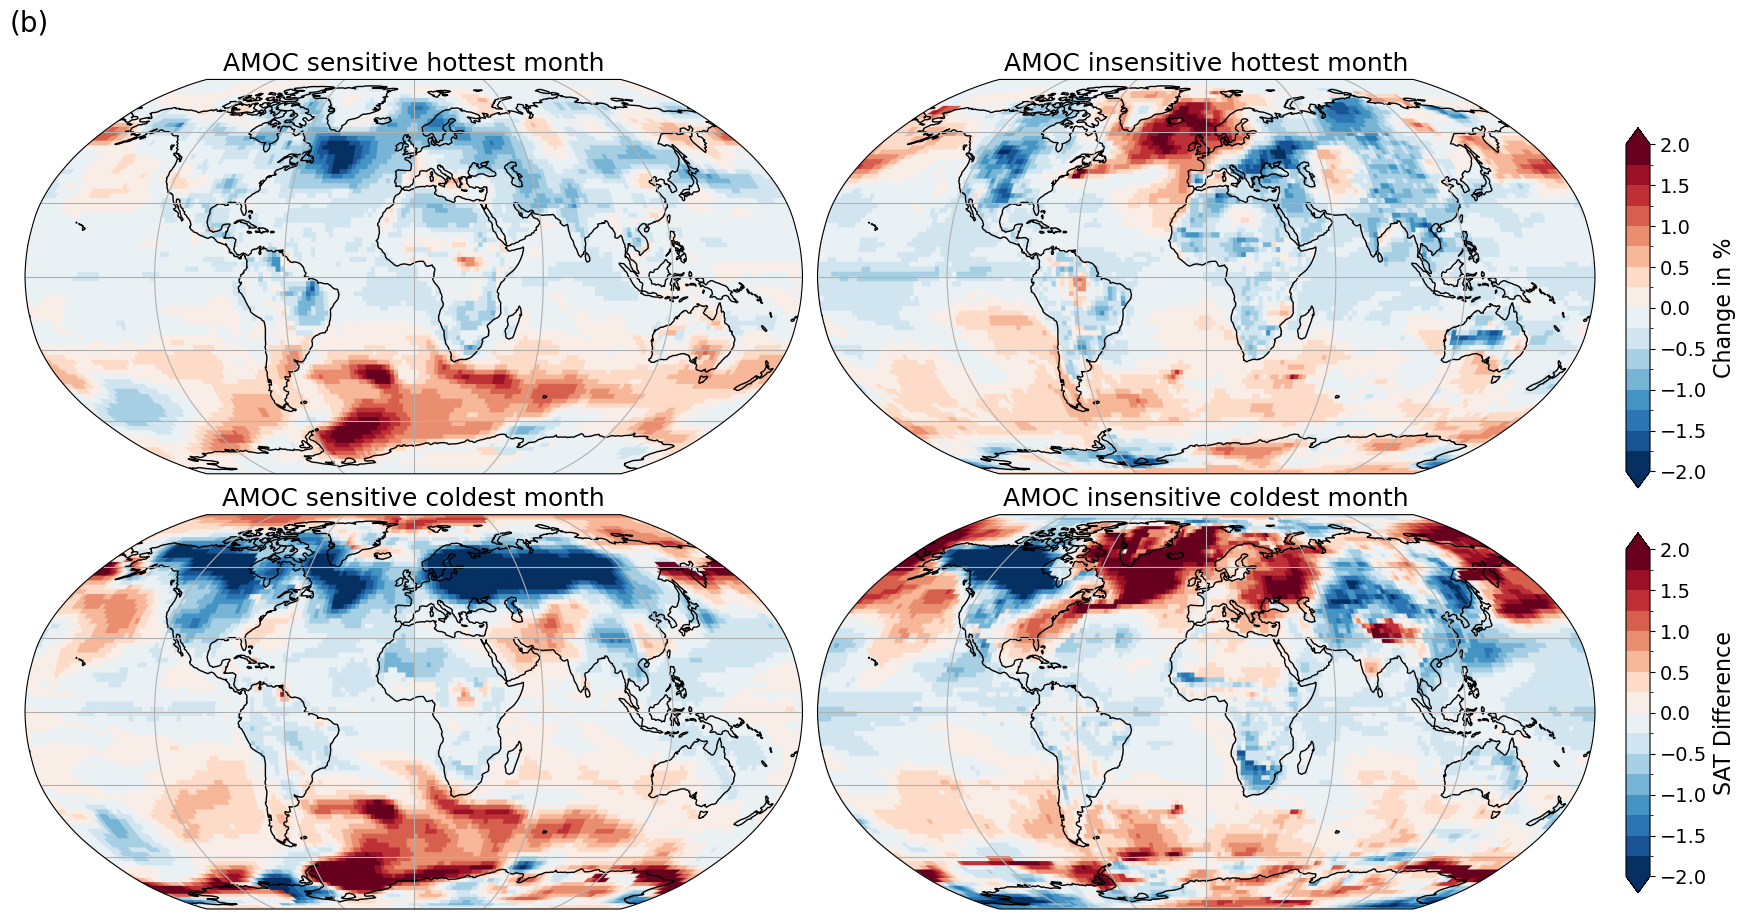

In [41]:
to_plot_heat = {
    'AMOC sensitive hottest month':AMOC_ext_month_tas_mean.sel(extrema='heat').isel(gwl=0),
    'AMOC insensitive hottest month':non_AMOC_ext_month_tas_mean.sel(extrema='heat').isel(gwl=0),
}
to_plot_cold = {
    'AMOC sensitive coldest month':AMOC_ext_month_tas_mean.sel(extrema='cold').isel(gwl=0),
    'AMOC insensitive coldest month':non_AMOC_ext_month_tas_mean.sel(extrema='cold').isel(gwl=0),
}

levels_heat = np.linspace(-2,2,17)
norm_heat = BoundaryNorm(levels_heat, ncolors=plt.cm.RdBu_r.N, clip=True)

levels_cold = np.linspace(-2,2,17)
norm_cold = BoundaryNorm(levels_cold, ncolors=plt.cm.RdBu.N, clip=True)

fig, axes = plt.subplots(2,2,subplot_kw={'projection': ccrs.Robinson()}, figsize=(16, 9))


for (model,da), ax in zip(to_plot_heat.items(),axes.flat[:2]):

    im = ax.imshow(
        da,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        norm=norm_heat,
        origin='lower',
        extent = (0,360,-90,90)
    )        
    ax.coastlines()
    ax.gridlines(draw_labels=False)
    ax.set_title(model,fontsize=18)

cbar_ax1 = fig.add_axes([1.01,0.5,0.015,0.4])
cbar1 = fig.colorbar(im,
                    cax=cbar_ax1,
                    **cbar_kwargs
                   )
cbar1.ax.tick_params(labelsize=14) 
cbar1.set_label("Change in %", fontsize=16)

for (model,da), ax in zip(to_plot_cold.items(),axes.flat[2:]):

    im = ax.imshow(
        da,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        norm=norm_cold,
        origin='lower',
        extent = (0,360,-90,90)
    )        
    # Add coastlines and grid
    ax.coastlines()
    ax.gridlines(draw_labels=False)
    ax.set_title(model,fontsize=18)

cbar_ax2 = fig.add_axes([1.01,0.05,0.015,0.4])
cbar2 = fig.colorbar(im,
                    cax=cbar_ax2,
                    **cbar_kwargs
                   )
cbar2.ax.tick_params(labelsize=14)
cbar2.set_label("SAT Difference", fontsize=16)

fig.text(0,1.0,
         '(b)',
         fontsize=20,
         va='bottom',
         ha='left'
        )

fig.tight_layout()